In [1]:
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated, Literal
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

In [35]:
llm = ChatGroq(
            model = 'openai/gpt-oss-120b',
            max_tokens = 700,
            temperature = 0.3
            )

In [36]:
class JokeState(TypedDict):

    topic : str
    joke : str
    explanation : str

In [49]:
def generate_joke(state : JokeState):

    prompt = f"Generate a joke on the given topic and make sure everytime you generate Joke on topic the joke should be unique not repeated, it should not be similar to it's previous Joke : {state['topic']}"
    response = llm.invoke(prompt).content

    return {'joke': response }

In [50]:
def explain_joke(state : JokeState):

    prompt = f"explain the joke generated : {state['joke']}"
    response = llm.invoke(prompt).content

    return {'explanation' : response}

In [51]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('explain_joke', explain_joke)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'explain_joke')
graph.add_edge('explain_joke', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

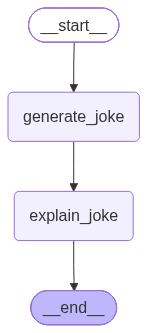

In [52]:
workflow

In [76]:
initial_state = {
    'topic' : "Indian Railway"
}

config = {"configurable" : {'thread_id':'1'}}
result = workflow.invoke(initial_state, config=config)
result 

{'topic': 'Indian Railway',
 'joke': 'Why did the Indian railway passenger bring a ladder on the train?  \n\nBecause he heard the tickets were “up‑graded” and wanted to be ready for the next “platform‑level” experience! 🚂😄',
 'explanation': '**What the joke is playing with**\n\n| Element in the joke | Literal meaning | Figurative / punny meaning |\n|---------------------|----------------|----------------------------|\n| **“up‑graded”** | A normal word meaning “improved” or “moved to a higher class.” | In the railway world “up‑grade” can also be heard as “up‑grade‑ed,” i.e., “up‑grade‑ed *up*,” suggesting you need to go *up* somewhere. |\n| **“platform‑level”** | The height of a train platform (the flat surface where passengers board and alight). | “Level” can also mean “stage” or “experience.” So “platform‑level experience” sounds like “a higher‑level experience.” |\n| **Ladder** | A tool for climbing to a higher height. | If you think you have to *go up* (because of “up‑graded”) and y

In [83]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'Indian Railway', 'joke': 'Why did the Indian railway passenger bring a ladder on the train?  \n\nBecause he heard the tickets were “up‑graded” and wanted to be ready for the next “platform‑level” experience! 🚂😄', 'explanation': '**What the joke is playing with**\n\n| Element in the joke | Literal meaning | Figurative / punny meaning |\n|---------------------|----------------|----------------------------|\n| **“up‑graded”** | A normal word meaning “improved” or “moved to a higher class.” | In the railway world “up‑grade” can also be heard as “up‑grade‑ed,” i.e., “up‑grade‑ed *up*,” suggesting you need to go *up* somewhere. |\n| **“platform‑level”** | The height of a train platform (the flat surface where passengers board and alight). | “Level” can also mean “stage” or “experience.” So “platform‑level experience” sounds like “a higher‑level experience.” |\n| **Ladder** | A tool for climbing to a higher height. | If you think you have to *go up* (because o

In [86]:
config2 = {
    "configurable": {
        "thread_id": "123"
    }
}
workflow.invoke({'topic' : 'Pizza'}, config=config2)

{'topic': 'Pizza',
 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the company was looking for someone who could really *deliver* on a “crust”‑worthy performance! 🍕😄',
 'explanation': '**The joke breaks down into a few layers of wordplay and a visual gag that makes it funny.**  \n\n---\n\n### 1. The Setup  \n> **“Why did the pizza apply for a job?”**  \n\nA pizza is an inanimate food item, so the idea of it “applying for a job” is already absurd. This sets the listener up for a punchline that will involve a pun or a play on words.\n\n---\n\n### 2. The Punchline  \n> **“Because it heard the company was looking for someone who could really *deliver* on a ‘crust’-worthy performance!”**  \n\n#### a. “Deliver”  \n- **Literal meaning:** In the food‑delivery world, pizzas are famously *delivered* to customers.  \n- **Figurative meaning:** In business jargon, “deliver” means to meet expectations or produce results (“deliver on a promise”).  \n\nThe joke swaps the business se

In [87]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'Indian Railway', 'joke': 'Why did the Indian railway passenger bring a ladder on the train?  \n\nBecause he heard the tickets were “up‑graded” and wanted to be ready for the next “platform‑level” experience! 🚂😄', 'explanation': '**What the joke is playing with**\n\n| Element in the joke | Literal meaning | Figurative / punny meaning |\n|---------------------|----------------|----------------------------|\n| **“up‑graded”** | A normal word meaning “improved” or “moved to a higher class.” | In the railway world “up‑grade” can also be heard as “up‑grade‑ed,” i.e., “up‑grade‑ed *up*,” suggesting you need to go *up* somewhere. |\n| **“platform‑level”** | The height of a train platform (the flat surface where passengers board and alight). | “Level” can also mean “stage” or “experience.” So “platform‑level experience” sounds like “a higher‑level experience.” |\n| **Ladder** | A tool for climbing to a higher height. | If you think you have to *go up* (because o

In [88]:
workflow.get_state({'configurable': {'thread_id' : 1}, 'checkpoint_id': "1f1e058c-b56d-6e70-8002-c899f2a6c1be"})

StateSnapshot(values={'topic': 'Indian Railway', 'joke': 'Why did the Indian railway passenger bring a ladder on the train?  \n\nBecause he heard the tickets were “up‑graded” and wanted to be ready for the next “platform‑level” experience! 🚂😄', 'explanation': '**What the joke is playing with**\n\n| Element in the joke | Literal meaning | Figurative / punny meaning |\n|---------------------|----------------|----------------------------|\n| **“up‑graded”** | A normal word meaning “improved” or “moved to a higher class.” | In the railway world “up‑grade” can also be heard as “up‑grade‑ed,” i.e., “up‑grade‑ed *up*,” suggesting you need to go *up* somewhere. |\n| **“platform‑level”** | The height of a train platform (the flat surface where passengers board and alight). | “Level” can also mean “stage” or “experience.” So “platform‑level experience” sounds like “a higher‑level experience.” |\n| **Ladder** | A tool for climbing to a higher height. | If you think you have to *go up* (because of

In [97]:
workflow.update_state({'configurable' : {'thread_id' : 1,  'checkpoint_id': "1f1e058c-b56d-6e70-8002-c899f2a6c1be", "checkpoint_ns": ""}}, {'topic': "Biryani"})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e05f5-bec1-67ae-8003-cf0af1b32cb6'}}

In [100]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Pizza', 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the company was looking for someone who could really *deliver* on a “crust”‑worthy performance! 🍕😄', 'explanation': '**The joke breaks down into a few layers of wordplay and a visual gag that makes it funny.**  \n\n---\n\n### 1. The Setup  \n> **“Why did the pizza apply for a job?”**  \n\nA pizza is an inanimate food item, so the idea of it “applying for a job” is already absurd. This sets the listener up for a punchline that will involve a pun or a play on words.\n\n---\n\n### 2. The Punchline  \n> **“Because it heard the company was looking for someone who could really *deliver* on a ‘crust’-worthy performance!”**  \n\n#### a. “Deliver”  \n- **Literal meaning:** In the food‑delivery world, pizzas are famously *delivered* to customers.  \n- **Figurative meaning:** In business jargon, “deliver” means to meet expectations or produce results (“deliver on a promise”).  \n\nThe joke s